<a href="https://colab.research.google.com/github/ngophuduc2806-jpg/Machine-Learning/blob/main/B%C3%A0i_T%E1%BA%ADp_v%E1%BB%81_nh%C3%A0___H%E1%BB%8Dc_M%C3%A1y_buoi1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PHẦN 2: BÀI TẬP VỀ NHÀ**

**Bài 1: Thay đổi điều kiện sinh dữ liệu (Tăng độ nhiễu và so sánh độ chính xác)**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
n_samples = 200
X = np.random.uniform(10, 100, (n_samples, 1))

# Thử nghiệm với các mức độ lệch chuẩn nhiễu (noise std) khác nhau
noise_levels = [10, 50, 150, 300]
results = []

for noise_std in noise_levels:
    noise = np.random.normal(0, noise_std, (n_samples, 1))
    y = 50 + 5 * X + noise

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append((noise_std, mse, r2))
    print(f"Nhiễu std = {noise_std:3d} | MSE: {mse:10.2f} | R2 Score: {r2:.4f}")

# Nhận xét kết quả:
# Khi độ nhiễu tăng cao, MSE tăng nhanh và chỉ số R^2 giảm mạnh, thể hiện mô hình giải thích được ít biến thiên hơn.

Nhiễu std =  10 | MSE:     108.46 | R2 Score: 0.9936
Nhiễu std =  50 | MSE:    2763.96 | R2 Score: 0.8573
Nhiễu std = 150 | MSE:   23440.95 | R2 Score: 0.5624
Nhiễu std = 300 | MSE:   74809.69 | R2 Score: -0.0436


Ngưỡng (Threshold)  Accuracy    Precision   Recall      F1-Score    
-----------------------------------------------------------------
0.2                 0.7833      0.7778      0.8485      0.8116      
0.3                 0.8000      0.8000      0.8485      0.8235      
0.4                 0.8000      0.8182      0.8182      0.8182      
0.5                 0.8333      0.8710      0.8182      0.8438      
0.6                 0.8167      0.8929      0.7576      0.8197      
0.7                 0.8167      0.9231      0.7273      0.8136      
0.8                 0.8000      0.9200      0.6970      0.7931      


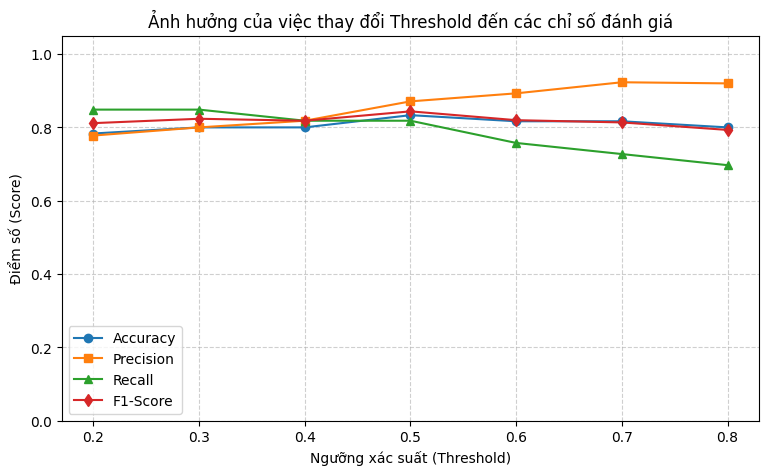

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# -------------------------------------------------------------
# BƯỚC 1: TẠO DỮ LIỆU GIẢ LẬP BMI & HUẤN LUYỆN LOGISTIC REGRESSION
# -------------------------------------------------------------
np.random.seed(42)

# Tạo 300 mẫu BMI từ 15 đến 40
n_samples = 300
bmi = np.random.uniform(15, 40, (n_samples, 1))

# Hàm sigmoid tạo xác suất mắc bệnh thực tế (ngưỡng chuyển giao quanh BMI = 27)
z = 0.45 * (bmi - 27)
prob = 1 / (1 + np.exp(-z))
y = np.random.binomial(1, prob).ravel()

# Chia tập Train / Test (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(bmi, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình Logistic Regression
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# -------------------------------------------------------------
# BƯỚC 2: THAY ĐỔI NGƯỠNG DỰ ĐOÁN XÁC SUẤT (THRESHOLD TUNING)
# -------------------------------------------------------------
# Lấy xác suất thuộc về nhãn 1 (Mắc bệnh) trên tập kiểm tra
probabilities = log_reg.predict_proba(X_test)[:, 1]

# Danh sách các ngưỡng cần khảo sát
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

print(f"{'Ngưỡng (Threshold)':<20}{'Accuracy':<12}{'Precision':<12}{'Recall':<12}{'F1-Score':<12}")
print("-" * 65)

acc_list, prec_list, rec_list, f1_list = [], [], [], []

for th in thresholds:
    # Quyết định nhãn dựa trên ngưỡng xác suất tùy chỉnh
    custom_pred = (probabilities >= th).astype(int)

    acc = accuracy_score(y_test, custom_pred)
    prec = precision_score(y_test, custom_pred, zero_division=0)
    rec = recall_score(y_test, custom_pred, zero_division=0)
    f1 = f1_score(y_test, custom_pred, zero_division=0)

    acc_list.append(acc)
    prec_list.append(prec)
    rec_list.append(rec)
    f1_list.append(f1)

    print(f"{th:<20.1f}{acc:<12.4f}{prec:<12.4f}{rec:<12.4f}{f1:<12.4f}")

# -------------------------------------------------------------
# BƯỚC 3: TRỰC QUAN HÓA SỰ THAY ĐỔI CỦA CÁC ĐỘ ĐO THEO NGƯỠNG
# -------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(thresholds, acc_list, marker='o', label='Accuracy')
plt.plot(thresholds, prec_list, marker='s', label='Precision')
plt.plot(thresholds, rec_list, marker='^', label='Recall')
plt.plot(thresholds, f1_list, marker='d', label='F1-Score')

plt.title("Ảnh hưởng của việc thay đổi Threshold đến các chỉ số đánh giá")
plt.xlabel("Ngưỡng xác suất (Threshold)")
plt.ylabel("Điểm số (Score)")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [3]:
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# 1. Tải tập dữ liệu Boston Housing từ OpenML
boston = fetch_openml(name="boston", version=1, as_frame=True)
X = boston.data
y = boston.target.astype(float)

# Xử lý các cột dạng categorical nếu có
X = pd.get_dummies(X, drop_first=True)

# 2. Phân chia tập dữ liệu thành tập huấn luyện (80%) và kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Huấn luyện mô hình Linear Regression
model_boston = LinearRegression()
model_boston.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model_boston.predict(X_test)

# 4. Tính toán các chỉ số đánh giá: MSE và R2 score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH BOSTON HOUSING ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.4f}")

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH BOSTON HOUSING ---
Mean Squared Error (MSE): 24.8184
R² Score: 0.6616
Root Mean Squared Error (RMSE): 4.9818
